In [1]:
import time
from collections import deque

# Road map: each city lists its neighbours with the distance in km
graph = {
    "A": {"B": 4, "C": 3},
    "B": {"A": 4, "D": 5, "E": 12},
    "C": {"A": 3, "E": 10, "F": 7},
    "D": {"B": 5, "G": 6},
    "E": {"B": 12, "C": 10, "G": 4},
    "F": {"C": 7, "G": 9},
    "G": {"D": 6, "E": 4, "F": 9},
}

# Heuristic: estimated distance from each city to the goal G
heuristic = {"A": 11, "B": 8, "C": 8, "D": 5, "E": 3, "F": 8, "G": 0}


def path_cost(graph, path):
    """Total road distance of a path."""
    return sum(graph[a][b] for a, b in zip(path, path[1:]))


def bfs(graph, start, goal):
    """Breadth First Search: finds the path with the fewest roads."""
    queue = deque([[start]])
    visited = {start}
    while queue:
        path = queue.popleft()
        node = path[-1]
        if node == goal:
            return path
        for neighbour in graph[node]:
            if neighbour not in visited:
                visited.add(neighbour)
                queue.append(path + [neighbour])
    return None


start_time = time.perf_counter()
bfs_path = bfs(graph, "A", "G")
bfs_time = time.perf_counter() - start_time

print("BFS path:", " -> ".join(bfs_path))
print("Cost:", path_cost(graph, bfs_path), "km")
print(f"Execution time: {bfs_time:.6f} seconds")

BFS path: A -> B -> D -> G
Cost: 15 km
Execution time: 0.000153 seconds


In [2]:
def dfs(graph, start, goal):
    """Depth First Search: goes as deep as possible before backtracking."""
    stack = [[start]]
    visited = set()
    while stack:
        path = stack.pop()
        node = path[-1]
        if node == goal:
            return path
        if node in visited:
            continue
        visited.add(node)
        for neighbour in graph[node]:
            if neighbour not in visited:
                stack.append(path + [neighbour])
    return None


start_time = time.perf_counter()
dfs_path = dfs(graph, "A", "G")
dfs_time = time.perf_counter() - start_time

print("DFS path:", " -> ".join(dfs_path))
print("Cost:", path_cost(graph, dfs_path), "km")
print(f"Execution time: {dfs_time:.6f} seconds")

DFS path: A -> C -> F -> G
Cost: 19 km
Execution time: 0.000152 seconds


In [3]:
def hill_climbing(graph, heuristic, start, goal):
    """Hill Climbing: always moves to the neighbour that looks closest
    to the goal. It never goes back, so it can get stuck.
    """
    path = [start]
    current = start
    while current != goal:
        best = min(graph[current], key=lambda city: heuristic[city])
        if heuristic[best] >= heuristic[current]:
            return path, False  # stuck at a local optimum
        path.append(best)
        current = best
    return path, True


start_time = time.perf_counter()
hc_path, hc_reached = hill_climbing(graph, heuristic, "A", "G")
hc_time = time.perf_counter() - start_time

print("Hill Climbing path:", " -> ".join(hc_path))
print("Reached goal:", hc_reached)
print("Cost:", path_cost(graph, hc_path), "km")
print(f"Execution time: {hc_time:.6f} seconds")

Hill Climbing path: A -> B -> E -> G
Reached goal: True
Cost: 20 km
Execution time: 0.000276 seconds


In [4]:
import heapq


def best_first_search(graph, heuristic, start, goal):
    """Best First Search: always expands the city with the lowest
    heuristic value among all cities waiting to be explored.
    """
    frontier = [(heuristic[start], [start])]
    visited = set()
    while frontier:
        _, path = heapq.heappop(frontier)
        node = path[-1]
        if node == goal:
            return path
        if node in visited:
            continue
        visited.add(node)
        for neighbour in graph[node]:
            if neighbour not in visited:
                heapq.heappush(
                    frontier, (heuristic[neighbour], path + [neighbour])
                )
    return None


start_time = time.perf_counter()
bfs_greedy_path = best_first_search(graph, heuristic, "A", "G")
bfs_greedy_time = time.perf_counter() - start_time

print("Best First Search path:", " -> ".join(bfs_greedy_path))
print("Cost:", path_cost(graph, bfs_greedy_path), "km")
print(f"Execution time: {bfs_greedy_time:.6f} seconds")

Best First Search path: A -> B -> E -> G
Cost: 20 km
Execution time: 0.000178 seconds


In [5]:
import heapq


def a_star(graph, heuristic, start, goal):
    """A* Search: expands the city with the lowest f = g + h, where
    g is the distance travelled so far and h is the heuristic estimate.
    """
    frontier = [(heuristic[start], 0, [start])]
    best_cost = {start: 0}
    while frontier:
        _, cost, path = heapq.heappop(frontier)
        node = path[-1]
        if node == goal:
            return path
        for neighbour, distance in graph[node].items():
            new_cost = cost + distance
            if neighbour not in best_cost or new_cost < best_cost[neighbour]:
                best_cost[neighbour] = new_cost
                f_value = new_cost + heuristic[neighbour]
                heapq.heappush(
                    frontier, (f_value, new_cost, path + [neighbour])
                )
    return None


start_time = time.perf_counter()
a_star_path = a_star(graph, heuristic, "A", "G")
a_star_time = time.perf_counter() - start_time

print("A* path:", " -> ".join(a_star_path))
print("Cost:", path_cost(graph, a_star_path), "km")
print(f"Execution time: {a_star_time:.6f} seconds")

A* path: A -> B -> D -> G
Cost: 15 km
Execution time: 0.000148 seconds


Matplotlib is building the font cache; this may take a moment.


Algorithm           Path              Cost (km)   Time (ms)
BFS                 A -> B -> D -> G  15          0.0040
DFS                 A -> C -> F -> G  19          0.0016
Hill Climbing       A -> B -> E -> G  20          0.0020
Best First Search   A -> B -> E -> G  20          0.0028
A*                  A -> B -> D -> G  15          0.0039


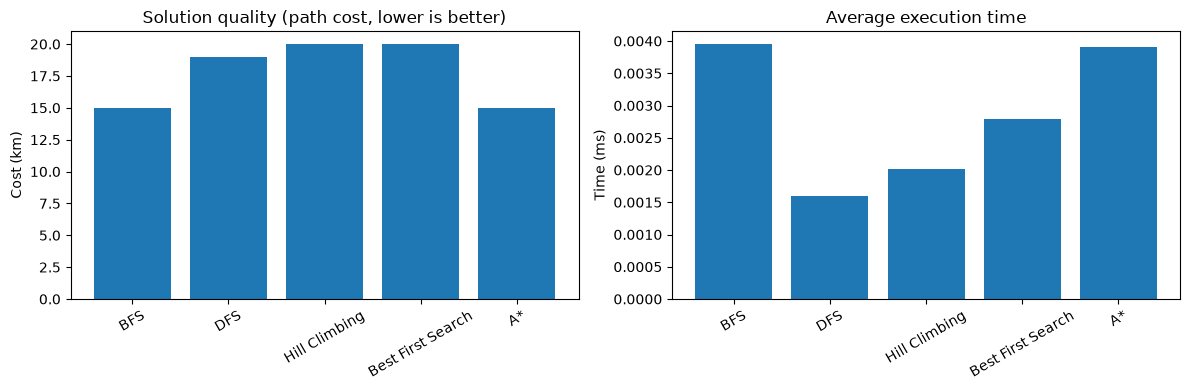

In [6]:
import matplotlib.pyplot as plt


def measure(function, *args, runs=1000):
    """Run a search many times; return its result and the average time in ms."""
    start_time = time.perf_counter()
    for _ in range(runs):
        result = function(*args)
    average_ms = (time.perf_counter() - start_time) / runs * 1000
    return result, average_ms


results = {}
results["BFS"] = measure(bfs, graph, "A", "G")
results["DFS"] = measure(dfs, graph, "A", "G")
hc_result, hc_ms = measure(hill_climbing, graph, heuristic, "A", "G")
results["Hill Climbing"] = (hc_result[0], hc_ms)
results["Best First Search"] = measure(
    best_first_search, graph, heuristic, "A", "G"
)
results["A*"] = measure(a_star, graph, heuristic, "A", "G")

print(f"{'Algorithm':<20}{'Path':<18}{'Cost (km)':<12}{'Time (ms)'}")
names, costs, times = [], [], []
for name, (path, ms) in results.items():
    cost = path_cost(graph, path)
    print(f"{name:<20}{' -> '.join(path):<18}{cost:<12}{ms:.4f}")
    names.append(name)
    costs.append(cost)
    times.append(ms)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(names, costs)
ax1.set_title("Solution quality (path cost, lower is better)")
ax1.set_ylabel("Cost (km)")
ax2.bar(names, times)
ax2.set_title("Average execution time")
ax2.set_ylabel("Time (ms)")
for axis in (ax1, ax2):
    axis.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("search_comparison.png")
plt.show()